# 3. Post-deployment shift

Compare two deployment windows with training data. Statistical drift is evidence of changed data, not automatically evidence of degraded model performance.

# focused analysis

**Goal:** characterize observed deployment drift, label-selection risk, and the robot-associated action-channel change; distinguish motion error from channel-6 error. Deployment samples are independent records, **not continuous episodes**. No deployment labels are used for training or tuning.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from ml_project.data import make_default_datasets
from ml_project.drift import compare_frames, dataset_frame

ROOT = next(
    (
        p
        for p in [Path.cwd(), *Path.cwd().parents]
        if (p / "pyproject.toml").is_file() and (p / "src" / "ml_project").is_dir()
    ),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Cannot locate repository root (pyproject.toml and src/ml_project)")
print("Repository root:", ROOT)
OUT = ROOT / "results" / "drift"
OUT.mkdir(parents=True, exist_ok=True)
datasets = make_default_datasets(train_size=512, validation_size=128, deployment_size=128)
frames = {name: dataset_frame(ds) for name, ds in datasets.items()}
clean_frames = {}
for split, frame in frames.items():
    frame = frame.copy()
    for camera in ("front", "wrist"):
        unavailable = ~frame[f"{camera}_available"].astype(bool)
        frame.loc[unavailable, [f"{camera}_mean", f"{camera}_std"]] = np.nan
    clean_frames[split] = frame
print("Loaded:", {k: len(v) for k, v in datasets.items()})

Repository root: C:\Users\parin\Documents\projects\ml-project-aliriahi90
Loaded: {'train': 512, 'validation': 128, 'deployment_week_1': 128, 'deployment_week_2': 128}


## 1. Monitoring overview

Exclude unavailable-camera placeholders from brightness and contrast statistics. Report label coverage and intervention rates for **all** records.

In [2]:
overview = pd.DataFrame(
    [
        {
            "split": split,
            "n": len(f),
            "n_labeled": int(f.label_available.sum()),
            "label_rate": f.label_available.mean(),
            "intervention_rate": f.intervention.mean(),
            "front_available_rate": f.front_available.mean(),
            "wrist_available_rate": f.wrist_available.mean(),
            "front_brightness": f.front_mean.mean(),
            "wrist_brightness_available_only": f.wrist_mean.mean(),
            "state_norm_mean": f.state_norm.mean(),
        }
        for split, f in clean_frames.items()
    ]
)
display(overview.round(4))
overview.to_csv(OUT / "monitoring_overview.csv", index=False)

,split,n,n_labeled,label_rate,intervention_rate,front_available_rate,wrist_available_rate,front_brightness,wrist_brightness_available_only,state_norm_mean
0,train,512,512,1.0000,0.0410,1.0,1.0000,0.1430,0.1431,0.5138
1,validation,128,128,1.0000,0.0312,1.0,1.0000,0.1432,0.1433,0.5047
2,deployment_week_1,128,29,0.2266,0.0469,1.0,1.0000,0.1314,0.1314,0.5204
3,deployment_week_2,128,33,0.2578,0.2578,1.0,0.7656,0.1611,0.1611,0.5099


## 2. Distribution drift relative to training

Continuous metrics compare available observations; categorical drift includes camera availability, robot identity, site and task. Drift alone does not establish model degradation.

In [3]:
continuous = [
    "state_norm",
    "state_x",
    "state_y",
    "front_mean",
    "front_std",
    "wrist_mean",
    "wrist_std",
    "prompt_length",
]
categorical = ["task", "site_id", "robot_id", "front_available", "wrist_available"]
rows = []
for split in ("deployment_week_1", "deployment_week_2"):
    res = compare_frames(
        clean_frames["train"],
        clean_frames[split],
        continuous_columns=continuous,
        categorical_columns=categorical,
    )
    for typ in ("continuous", "categorical"):
        for feature, values in res[typ].items():
            rows.append({"split": split, "type": typ, "feature": feature, **values})
drift = pd.DataFrame(rows)
for typ, score in [("continuous", "ks_statistic"), ("categorical", "total_variation")]:
    print(typ.upper())
    display(drift[drift.type.eq(typ)].sort_values(["split", score], ascending=[True, False]))
drift.to_csv(OUT / "distribution_shift.csv", index=False)

CONTINUOUS


,split,type,feature,ks_statistic,wasserstein,psi,total_variation,jensen_shannon_divergence
3,deployment_week_1,continuous,front_mean,1.000000,0.011628,12.396795,NaN,NaN
5,deployment_week_1,continuous,wrist_mean,1.000000,0.011672,12.396795,NaN,NaN
6,deployment_week_1,continuous,wrist_std,0.876953,0.016626,11.010214,NaN,NaN
4,deployment_week_1,continuous,front_std,0.869141,0.016514,11.010214,NaN,NaN
7,deployment_week_1,continuous,prompt_length,0.476562,1.906250,0.000000,NaN,NaN
0,deployment_week_1,continuous,state_norm,0.085938,0.011888,0.070496,NaN,NaN
2,deployment_week_1,continuous,state_y,0.078125,0.034752,0.049393,NaN,NaN
1,deployment_week_1,continuous,state_x,0.076172,0.024276,0.049846,NaN,NaN
16,deployment_week_2,continuous,front_mean,1.000000,0.018074,12.396795,NaN,NaN
18,deployment_week_2,continuous,wrist_mean,1.000000,0.018006,12.396795,NaN,NaN


CATEGORICAL


,split,type,feature,ks_statistic,wasserstein,psi,total_variation,jensen_shannon_divergence
9,deployment_week_1,categorical,site_id,NaN,NaN,NaN,1.000000,1.000000
8,deployment_week_1,categorical,task,NaN,NaN,NaN,0.152344,0.020867
10,deployment_week_1,categorical,robot_id,NaN,NaN,NaN,0.000000,0.000000
11,deployment_week_1,categorical,front_available,NaN,NaN,NaN,0.000000,0.000000
12,deployment_week_1,categorical,wrist_available,NaN,NaN,NaN,0.000000,0.000000
22,deployment_week_2,categorical,site_id,NaN,NaN,NaN,1.000000,1.000000
23,deployment_week_2,categorical,robot_id,NaN,NaN,NaN,1.000000,1.000000
21,deployment_week_2,categorical,task,NaN,NaN,NaN,0.384766,0.131441
25,deployment_week_2,categorical,wrist_available,NaN,NaN,NaN,0.234375,0.128442
24,deployment_week_2,categorical,front_available,NaN,NaN,NaN,0.000000,0.000000


## 3. Are deployment labels representative?

Compare labeled and unlabeled records using features observed for **both** groups. These checks can reveal selection bias but cannot establish that labels are missing at random.

In [4]:
coverage = []
for split in ("deployment_week_1", "deployment_week_2"):
    f = clean_frames[split].copy()
    f["labeled"] = f.label_available.astype(bool)
    coverage.append(
        {
            "split": split,
            "n": len(f),
            "n_labeled": int(f.labeled.sum()),
            "label_rate": f.labeled.mean(),
        }
    )
    print("\n", split)
    for feature in ("task", "intervention", "wrist_available"):
        print(feature)
        display(pd.crosstab(f["labeled"], f[feature], normalize="index").round(3))
    display(
        f.groupby("labeled")[["state_norm", "front_mean", "wrist_mean"]]
        .agg(["count", "mean", "std"])
        .round(3)
    )
coverage = pd.DataFrame(coverage)
display(coverage)
coverage.to_csv(OUT / "label_coverage.csv", index=False)


 deployment_week_1
task


task,blue_to_green,blue_to_red,blue_to_yellow,green_to_blue,green_to_red,green_to_yellow,red_to_blue,red_to_green,red_to_yellow,yellow_to_blue,yellow_to_green,yellow_to_red
labeled,,,,,,,,,,,,
False,0.101,0.061,0.071,0.121,0.121,0.091,0.081,0.121,0.040,0.030,0.111,0.051
True,0.034,0.138,0.034,0.000,0.172,0.138,0.103,0.138,0.103,0.103,0.000,0.034


intervention


intervention,False,True
labeled,,
False,0.960,0.040
True,0.931,0.069


wrist_available


wrist_available,True
labeled,
False,1.0
True,1.0


... (5 outputs left out)

wrist_available


wrist_available,False,True
labeled,,
False,0.232,0.768
True,0.242,0.758


state_norm               front_mean               wrist_mean         \
             count   mean    std      count   mean    std      count   mean   
labeled                                                                       
False           95  0.514  0.088         95  0.161  0.001         73  0.161   
True            33  0.499  0.076         33  0.161  0.001         25  0.161   

                
           std  
labeled         
False    0.001  
True     0.001

,split,n,n_labeled,label_rate
0,deployment_week_1,128,29,0.226562
1,deployment_week_2,128,33,0.257812


## 4. Robot-associated action-channel-6 shift

Only labeled examples contribute to action statistics. Show both across-sample chunk-mean variability and within-chunk variation: a constant chunk mean does **not** mean the channel is constant over time. Robot and week are confounded.

In [5]:
robot_rows = []
for split in ("train", "validation", "deployment_week_1", "deployment_week_2"):
    for i in range(len(datasets[split])):
        s = datasets[split][i]
        if not bool(s["action_mask"]):
            continue
        y = np.asarray(s["actions"], dtype=float)
        robot_rows.append(
            {
                "split": split,
                "robot_id": str(s["metadata"]["robot_id"]),
                "chunk_mean": y[:, 6].mean(),
                "chunk_std": y[:, 6].std(),
                "first": y[0, 6],
                "last": y[-1, 6],
            }
        )
robot_targets = pd.DataFrame(robot_rows)
robot_audit = robot_targets.groupby(["split", "robot_id"], as_index=False).agg(
    n=("chunk_mean", "size"),
    mean_dim6=("chunk_mean", "mean"),
    std_of_chunk_means=("chunk_mean", "std"),
    mean_within_chunk_std=("chunk_std", "mean"),
    first=("first", "mean"),
    last=("last", "mean"),
)
display(robot_audit.fillna(0).round(5))
robot_audit.to_csv(OUT / "robot_action_audit.csv", index=False)

,split,robot_id,n,mean_dim6,std_of_chunk_means,mean_within_chunk_std,first,last
0,deployment_week_1,robot_01,29,0.375,0.0,0.69597,0.0,-1.0
1,deployment_week_2,robot_03,33,-0.375,0.0,0.69597,0.0,1.0
2,train,robot_01,512,0.375,0.0,0.69597,0.0,-1.0
3,validation,robot_01,128,0.375,0.0,0.69597,0.0,-1.0


## 5. Model performance and error decomposition

Use previously generated **clean-condition** evaluation artifacts rather than repeating expensive model inference. Compare overall action MSE, motion-only MSE (dimensions 0–5), and dimension-6 MSE separately. Missing files are reported explicitly; no metrics are fabricated.

Per-dimension file: C:\Users\parin\Documents\projects\ml-project-aliriahi90\results\modality_diagnostics\clean_dimension_summary.csv | exists: True
Statistical baseline file: C:\Users\parin\Documents\projects\ml-project-aliriahi90\results\simple_baselines\summary.csv | exists: True
Per-dimension columns: ['model', 'split', 'dimension', 'action_mse', 'pred_smoothness', 'target_smoothness', 'temporal_difference_mse']
Statistical baseline columns: ['model', 'split', 'n_labeled', 'mse', 'mse_motion_0_5', 'mse_dim6', 'endpoint_error', 'pred_smoothness', 'target_smoothness', 'temporal_difference_mse', 'task_coverage']


,model,split,mse_motion_0_5,mse_dim6,mse
14,state_ridge,deployment_week_1,0.005225,0.000000,0.004478
12,global_mean,deployment_week_1,0.005864,0.000000,0.005026
13,task_mean,deployment_week_1,0.006040,0.000000,0.005177
3,cross_full,deployment_week_1,0.019210,0.031199,0.020923
0,baseline,deployment_week_1,0.020582,0.093921,0.031059
1,baseline,deployment_week_2,0.022902,2.152460,0.327124
17,state_ridge,deployment_week_2,0.005963,2.500000,0.362254
16,task_mean,deployment_week_2,0.006224,2.500000,0.362478
15,global_mean,deployment_week_2,0.006516,2.500000,0.362728
4,cross_full,deployment_week_2,0.018657,2.678909,0.398693


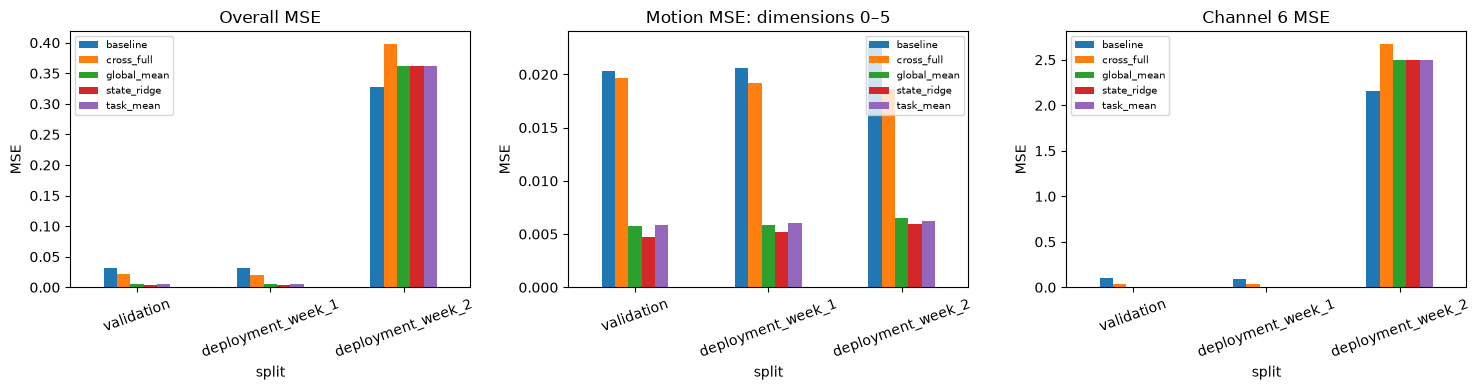

In [6]:
# Read only the saved evaluation artifacts used by this assessment.
# All paths are relative to the repository root, not notebooks/.
per_dim_path = ROOT / "results" / "modality_diagnostics" / "clean_dimension_summary.csv"
stat_path = ROOT / "results" / "simple_baselines" / "summary.csv"

print("Per-dimension file:", per_dim_path, "| exists:", per_dim_path.is_file())
print("Statistical baseline file:", stat_path, "| exists:", stat_path.is_file())

parts = []
if per_dim_path.is_file():
    d = pd.read_csv(per_dim_path)
    print("Per-dimension columns:", d.columns.tolist())
    # Use the recorded clean-condition per-dimension action MSE.
    required = {"model", "split", "dimension"}
    mse_col = next((x for x in ("action_mse", "mse", "mse_action") if x in d.columns), None)
    if not required.issubset(d.columns) or mse_col is None:
        raise ValueError(f"Unexpected per-dimension schema: {d.columns.tolist()}")
    if "condition" in d.columns:
        d = d[d["condition"].astype(str).eq("clean")]
    d = d[pd.to_numeric(d["dimension"], errors="coerce").between(0, 6)].copy()
    d["dimension"] = d["dimension"].astype(int)
    for (model, split), g in d.groupby(["model", "split"]):
        if set(g["dimension"]) != set(range(7)) or g["dimension"].duplicated().any():
            print("Skipping incomplete/duplicate dimensions:", model, split)
            continue
        by_dim = g.set_index("dimension")[mse_col].astype(float)
        motion = float(by_dim.loc[list(range(6))].mean())
        dim6 = float(by_dim.loc[6])
        parts.append(
            {
                "model": model,
                "split": split,
                "mse_motion_0_5": motion,
                "mse_dim6": dim6,
                "mse": (6 * motion + dim6) / 7,
            }
        )
else:
    print("Missing:", per_dim_path)

if stat_path.is_file():
    s = pd.read_csv(stat_path)
    print("Statistical baseline columns:", s.columns.tolist())
    needed = {"model", "split", "mse", "mse_motion_0_5", "mse_dim6"}
    if needed.issubset(s.columns):
        parts.extend(s[list(needed)].to_dict("records"))
    else:
        raise ValueError(f"Statistical baseline schema missing {sorted(needed - set(s.columns))}")
else:
    print("Missing:", stat_path)

comparison = pd.DataFrame(parts, columns=["model", "split", "mse_motion_0_5", "mse_dim6", "mse"])
if comparison.empty:
    raise RuntimeError("No model performance evidence loaded. Check the two file paths above.")
comparison = comparison.drop_duplicates(["model", "split"], keep="last")
display(comparison.sort_values(["split", "mse"]).round(6))
comparison.to_csv(OUT / "model_error_decomposition.csv", index=False)

required_splits = {"deployment_week_1", "deployment_week_2"}
missing = required_splits - set(comparison["split"].astype(str))
if missing:
    raise RuntimeError(
        f"Missing deployment evaluation for: {sorted(missing)}. "
        "Check the saved CSV split labels and evaluation outputs."
    )

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
order = ["validation", "deployment_week_1", "deployment_week_2"]
for ax, col, title in zip(
    axes,
    ["mse", "mse_motion_0_5", "mse_dim6"],
    ["Overall MSE", "Motion MSE: dimensions 0–5", "Channel 6 MSE"],
    strict=True,
):
    pivot = comparison.pivot(index="split", columns="model", values=col).reindex(order)
    pivot.plot.bar(ax=ax, rot=20, title=title)
    ax.set_ylabel("MSE")
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

## 6. Required structured drift report

Generate `results/drift_report.json` from the calculated monitoring, distribution-shift, labeled performance, and robot-slice results. Missing model-evaluation evidence is explicitly flagged rather than filled in.

In [7]:
# Required take-home deliverable: results/drift_report.json.
# All numerical values below are computed from the loaded frozen datasets
# and previously saved evaluation files; unavailable model results are not invented.
import json


def records_json(df):
    if df is None or df.empty:
        return []
    return json.loads(df.replace([np.inf, -np.inf], np.nan).to_json(orient="records"))


model_splits = set(comparison["split"].astype(str)) if not comparison.empty else set()
required_splits = {"deployment_week_1", "deployment_week_2"}
missing_perf = sorted(required_splits - model_splits)
if missing_perf:
    raise RuntimeError(
        f"Cannot generate a complete drift report; missing performance: {missing_perf}"
    )

recommendations = {
    "deployment_week_1": {
        "action": "continue monitoring and collect targeted labels",
        "reason": (
            "Evaluate observed covariate and missing-camera changes separately "
            "from measured action-prediction error; account for limited "
            "labeled coverage."
        ),
    },
    "deployment_week_2": {
        "action": (
            "verify robot/action schema before rollout; collect targeted "
            "labels and investigate channel 6"
        ),
        "reason": (
            "Robot identity and deployment window are confounded. "
            "A change in channel-6 labels does not establish "
            "a physical actuator sign convention."
        ),
    },
}

report = {
    "reference_split": "train",
    "deployment_windows": ["deployment_week_1", "deployment_week_2"],
    "unit_of_observation": (
        "independent observation-action sample with an 8x7 future action chunk; not an episode"
    ),
    "methods": {
        "distribution_comparison": (
            "compare_frames on continuous and categorical features; KS "
            "statistic and total variation where supplied by evaluator"
        ),
        "missing_camera_handling": (
            "exclude unavailable camera placeholders from brightness and contrast statistics"
        ),
        "performance": (
            "action MSE by dimension on labeled samples only, using saved evaluation outputs"
        ),
        "label_selection": (
            "compare observed covariates for labeled and unlabeled deployment records"
        ),
        "caveats": [
            "small labeled deployment subsets",
            "robot identity confounded with week",
            "offline action error is not closed-loop success",
        ],
    },
    "monitoring_overview": records_json(overview),
    "detected_shifts": records_json(drift),
    "label_coverage": records_json(coverage),
    "robot_action_slices": records_json(robot_audit),
    "performance_evidence": records_json(comparison),
    "performance_evidence_complete": not missing_perf,
    "missing_performance_windows": missing_perf,
    "recommendations": recommendations,
}
report_path = ROOT / "results" / "drift_report.json"
report_path.write_text(json.dumps(report, indent=2, allow_nan=False), encoding="utf-8")
print("Saved:", report_path)
print(
    "Drift rows:",
    len(report["detected_shifts"]),
    "| Performance rows:",
    len(report["performance_evidence"]),
)

Saved: C:\Users\parin\Documents\projects\ml-project-aliriahi90\results\drift_report.json
Drift rows: 26 | Performance rows: 18


## 7. Decision and limitations

| Finding | Supported interpretation | Operational action |
|---|---|---|
| Camera brightness and missingness changes | Covariate shift, not automatically performance degradation | Monitor availability and labeled performance slices |
| Robot_03 occurs in week 2 with reversed channel-6 mean | Robot-associated action-target shift; physical semantics unverified | Check action schema and robot adapter before any deployment correction |
| Sparse deployment labels | Possible selection bias and uncertainty | Report labeled sample counts and observable selection differences |
| Motion-only and overall MSE disagree | One channel can dominate aggregate error | Monitor both motion-only and channel-6 errors |
| Modality shuffling barely changes MSE (from Experiment 5) | Potential action-prior shortcut; not proof of absent grounding | Retain global-mean/state-only controls and test prediction sensitivity |

**Limitations:** Deployment records are independent samples, not full episodes. Do not infer closed-loop success. Never apply the diagnostic channel-6 sign flip to robot commands without interface verification.